# Trabajo Parcial - CC219 Aplicaciones de Data Science
## Avisos inmobiliarios del Perú: análisis exploratorio y línea base con NLP

Integrantes:
1. Juan Felipe Granados Allende - U202212216
2. David Miguel Ramos Parihuaman - U202417368
3. Renee Enriquez Montalvan - U202221447

Sección CC92 - Ciclo 2026-2

Objetivo del notebook: cargar, inspeccionar, limpiar y normalizar los avisos inmobiliarios del Perú publicados en Properati (dataset de Kaggle), hacer el análisis exploratorio y una validación preliminar de los modelos que proponemos para el trabajo final.

Preguntas del caso de uso:
- P1 (clasificación): ¿se puede identificar el tipo de inmueble (departamento, casa, lote, local comercial u oficina) solo con el título y la descripción del aviso, y así reclasificar los avisos registrados como "Otro"?
- P2 (predicción): ¿se puede predecir el segmento de precio (económico, medio o alto) de un departamento en venta en Lima Metropolitana usando solo el texto del aviso? ¿qué palabras pesan más?
- P3 (recomendación): dada una búsqueda escrita en lenguaje natural, ¿qué avisos conviene recomendar? ¿la búsqueda semántica con embeddings funciona mejor que la búsqueda por palabras?
- P4 (adicional): ¿se pueden completar los datos que faltan (dormitorios, baños, área) extrayéndolos del texto?

Dataset: Property Listings for 5 South American Countries (Jacobsen, 2020), archivo pe_properties.csv, datos originales de Properati Data.

## 0. Librerías

La primera celda es para Colab (instala faiss y kagglehub). Si se corre en local se puede saltar.

In [ ]:
!pip -q install -U faiss-cpu kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 91.0 MB/s eta 0:00:00


In [ ]:
import os, re, html, unicodedata, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10})
SEED = 42
os.makedirs('figs', exist_ok=True)
os.makedirs('data', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'figs/{nombre}.png')

COLORES_TIPO = {'Departamento': '#4C72B0', 'Casa': '#DD8452', 'Lote': '#55A868', 'Local comercial': '#C44E52',
                'Oficina': '#8172B3', 'Otro': '#937860', 'Depósito': '#DA8BC3', 'Minoritarios (PH, cochera, casa de campo)': '#8C8C8C'}
COLORES_SEG = {'económico': '#55A868', 'medio': '#4C72B0', 'alto': '#C44E52'}

## 1. Carga de datos

Se usa kagglehub para bajar solo el archivo de Perú (pe_properties.csv) del dataset público. No pide credenciales. Si el archivo ya está en la carpeta data (por ejemplo, subido a mano o clonado del repositorio de GitHub, donde está comprimido como pe_properties.csv.xz) se lee desde ahí.

In [ ]:
ARCHIVO = 'data/pe_properties.csv'
DATASET = 'rmjacobsen/property-listings-for-5-south-american-countries'
# si se clono el repositorio, el original esta comprimido en la carpeta data
locales = [ARCHIVO, 'data/pe_properties.csv.xz', '../data/pe_properties.csv.xz']
existentes = [p for p in locales if os.path.exists(p)]
if existentes:
    ruta = existentes[0]
else:
    try:
        import kagglehub
        ruta = kagglehub.dataset_download(DATASET, path='pe_properties.csv')
    except Exception as e:
        # plan B: descarga directa del archivo desde la API publica de Kaggle
        print('kagglehub falló:', e)
        import requests, zipfile, io
        r = requests.get(f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}/pe_properties.csv', timeout=120)
        zipfile.ZipFile(io.BytesIO(r.content)).extractall('data')
        ruta = ARCHIVO
df_raw = pd.read_csv(ruta)
print('Archivo:', ruta)
print('Filas y columnas:', df_raw.shape)
df_raw.head(3).T

100%|██████████| 31.8M/31.8M [00:00<00:00, 36.7MB/s]

Extracting zip of pe_properties.csv...


Archivo: /root/.cache/kagglehub/datasets/rmjacobsen/property-listings-for-5-south-american-countries/versions/1/pe_properties.csv
Filas y columnas: (124449, 25)


,0,1,2
id,OHnwRj8WCByyWFlzr8CG2w==,+r81Zjmgyd2Y+cguWfoHhw==,TP2j5KyjkY1glXvrCBoqkA==
ad_type,Propiedad,Propiedad,Propiedad
start_date,2019-06-25,2019-06-25,2019-06-25
end_date,2019-07-23,2019-12-25,2019-09-03
created_on,2019-06-25,2019-06-25,2019-06-25
lat,-12.094636,-12.094851,-12.071644
lon,-77.003267,-77.017706,-77.037922
l1,Perú,Perú,Perú
l2,Lima,Lima,Lima
l3,Lima,Lima,Lima


## 2. Inspección de los datos

In [ ]:
resumen = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'no_nulos': df_raw.notna().sum(),
    'pct_nulos': (df_raw.isna().mean() * 100).round(1),
    'valores_unicos': df_raw.nunique()
})
resumen

,tipo,no_nulos,pct_nulos,valores_unicos
id,object,124449,0.0,124449
ad_type,object,124449,0.0,1
start_date,object,124449,0.0,388
end_date,object,124449,0.0,439
created_on,object,124449,0.0,388
lat,float64,118118,5.1,41878
lon,float64,118118,5.1,41254
l1,object,124449,0.0,1
l2,object,124449,0.0,25
l3,object,119496,4.0,86


In [ ]:
for col in ['ad_type', 'l1', 'operation_type', 'property_type', 'currency', 'price_period']:
    print(f'--- {col}')
    print(df_raw[col].value_counts(dropna=False).to_string(), '\n')

--- ad_type
ad_type
Propiedad    124449 

--- l1
l1
Perú    124449 

--- operation_type
operation_type
Venta                90980
Alquiler             33459
Alquiler temporal       10 

--- property_type
property_type
Departamento       51299
Otro               24670
Casa               20750
Lote               12669
Local comercial     8361
Oficina             6010
Depósito             645
PH                    28
Casa de campo         10
Cochera                7 

--- currency
currency
USD    98379
PEN    23028
NaN     3039
ARS        3 

--- price_period
price_period
NaN        65029
Mensual    59420 



In [ ]:
print('Rango de fechas de publicación:', df_raw.start_date.min(), 'a', df_raw.start_date.max())
print('Ids repetidos:', df_raw.id.duplicated().sum())
print('Avisos con título y descripción idénticos a otro:', df_raw.duplicated(['title', 'description']).sum())
print('Descripciones vacías:', (df_raw.description.fillna('').str.strip() == '').sum())
print('Avisos sin precio:', df_raw.price.isna().sum())
df_raw[['price', 'surface_total', 'surface_covered', 'bedrooms', 'bathrooms', 'rooms']].describe(
    percentiles=[.01, .5, .99]).round(1)

Rango de fechas de publicación: 2019-03-01 a 2020-03-24
Ids repetidos: 0
Avisos con título y descripción idénticos a otro: 21024
Descripciones vacías: 5
Avisos sin precio: 2397


,price,surface_total,surface_covered,bedrooms,bathrooms,rooms
count,122052.0,80361.0,50549.0,41447.0,87501.0,31989.0
mean,394655.1,740.4,16171.3,3.3,2.8,3.4
std,1807121.9,9561.5,3066074.8,2.4,1.8,2.5
min,0.0,10.0,1.0,0.0,1.0,1.0
1%,400.0,18.0,9.0,0.0,1.0,1.0
50%,118000.0,128.0,125.0,3.0,2.0,3.0
99%,4800000.0,7322.0,12492.3,12.0,10.0,16.0
max,133481430.0,500000.0,687975640.0,50.0,20.0,20.0


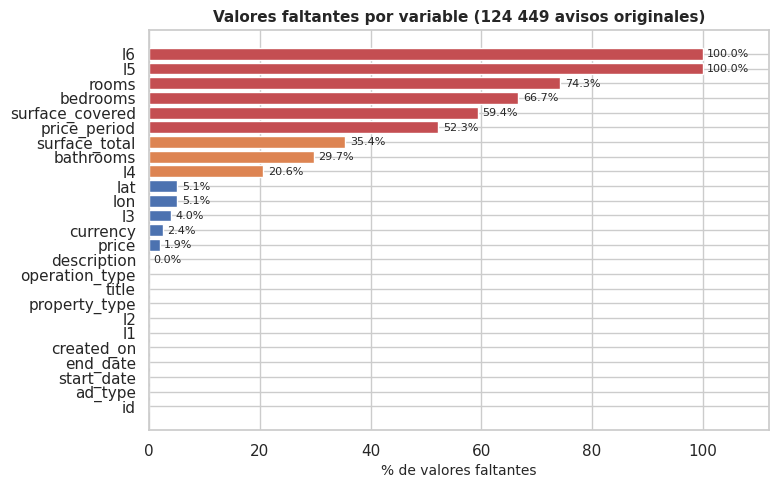

In [ ]:
# Porcentaje de valores faltantes por variable (datos originales)
nulos = (df_raw.isna().mean() * 100).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 5.2))
colores = ['#C44E52' if v >= 50 else ('#DD8452' if v >= 20 else '#4C72B0') for v in nulos.values]
ax.barh(nulos.index, nulos.values, color=colores)
for i, v in enumerate(nulos.values):
    if v > 0:
        ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=8)
ax.set_xlabel('% de valores faltantes')
ax.set_xlim(0, 112)
ax.set_title('Valores faltantes por variable (124 449 avisos originales)')
guardar('nulos_por_variable'); plt.show()

Lo que sale de la inspección:
- Son 124 449 avisos de todo el Perú publicados entre marzo de 2019 y marzo de 2020, con 25 columnas. Todos son de tipo Propiedad y del país Perú, así que ad_type y l1 no aportan nada.
- Hay 21 024 avisos que repiten exactamente el mismo título y la misma descripción (el mismo aviso subido varias veces), hay que sacarlos.
- Faltan muchos datos estructurados: dormitorios (66.7 %), área techada (59.4 %), área total (35.4 %) y baños (29.7 %). l5 y l6 están vacías. En cambio el título y la descripción están en casi todos los avisos, por eso el texto termina siendo la fuente más completa.
- Los precios tienen valores raros (mínimo 0 y máximo de 133 millones) y vienen en dos monedas (USD y PEN), así que para analizar precios hay que filtrar por moneda y quitar extremos.

## 3. Preprocesamiento

### 3.1 Limpieza de registros

Pasos: quitar avisos repetidos (mismo título y misma descripción), quitar descripciones vacías, borrar columnas que no aportan (l5 y l6 están vacías, ad_type y l1 tienen un solo valor) y renombrar la ubicación.

In [ ]:
pasos = [('Datos originales', len(df_raw))]
df = df_raw.drop_duplicates(subset=['title', 'description']).copy()
pasos.append(('Sin avisos duplicados (título + descripción)', len(df)))
df = df[df.description.fillna('').str.strip().str.len() > 0]
pasos.append(('Sin descripciones vacías', len(df)))

df = df.drop(columns=['l5', 'l6', 'ad_type', 'l1'])
df = df.rename(columns={'l2': 'region', 'l3': 'provincia', 'l4': 'distrito'})
df['start_date'] = pd.to_datetime(df['start_date'])
df['es_lima_metro'] = (df.region == 'Lima') & (df.provincia == 'Lima')
df['tipo'] = df.property_type.replace({'PH': 'Minoritarios (PH, cochera, casa de campo)', 'Cochera': 'Minoritarios (PH, cochera, casa de campo)',
                                       'Casa de campo': 'Minoritarios (PH, cochera, casa de campo)'})
df = df.reset_index(drop=True)
pd.DataFrame(pasos, columns=['paso', 'avisos'])

,paso,avisos
0,Datos originales,124449
1,Sin avisos duplicados (título + descripción),103425
2,Sin descripciones vacías,103423


### 3.2 Normalización de textos

El título y la descripción se juntan en un solo texto. Se generan dos versiones:

- texto_modelo: limpieza ligera para transformers y embeddings. Se quitan etiquetas HTML, enlaces, correos y teléfonos (anonimización) y se enmascaran los montos de precio con la marca [MONTO] para que el modelo de la P2 no "haga trampa" leyendo el precio escrito en el aviso. Se mantienen mayúsculas, tildes y signos porque los transformers sí los aprovechan.
- texto_norm: normalización completa para TF-IDF, BM25 y conteos: minúsculas, sin tildes (se conserva la ñ), unidades de área unificadas como m2, sin signos de puntuación y sin stopwords del español.

In [ ]:
try:
    import nltk
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOP_ES = stopwords.words('spanish')
except Exception:
    # misma lista de NLTK por si no hay conexión
    STOP_ES = '''de la que el en y a los del se las por un para con no una su al lo como más pero sus le ya o este sí porque esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos durante todos uno les ni contra otros ese eso ante ellos e esto mí antes algunos qué unos yo otro otras otra él tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas algo nosotros mi mis tú te ti tu tus ellas nosotras vosotros vosotras os mío mía míos mías tuyo tuya tuyos tuyas suyo suya suyos suyas nuestro nuestra nuestros nuestras vuestro vuestra vuestros vuestras esos esas estoy estás está estamos estáis están esté estés estemos estéis estén estaré estarás estará estaremos estaréis estarán estaría estarías estaríamos estaríais estarían estaba estabas estábamos estabais estaban estuve estuviste estuvo estuvimos estuvisteis estuvieron estuviera estuvieras estuviéramos estuvierais estuvieran estuviese estuvieses estuviésemos estuvieseis estuviesen estando estado estada estados estadas estad he has ha hemos habéis han haya hayas hayamos hayáis hayan habré habrás habrá habremos habréis habrán habría habrías habríamos habríais habrían había habías habíamos habíais habían hube hubiste hubo hubimos hubisteis hubieron hubiera hubieras hubiéramos hubierais hubieran hubiese hubieses hubiésemos hubieseis hubiesen habiendo habido habida habidos habidas soy eres es somos sois son sea seas seamos seáis sean seré serás será seremos seréis serán sería serías seríamos seríais serían era eras éramos erais eran fui fuiste fue fuimos fuisteis fueron fuera fueras fuéramos fuerais fueran fuese fueses fuésemos fueseis fuesen sintiendo sentido sentida sentidos sentidas siente sentid tengo tienes tiene tenemos tenéis tienen tenga tengas tengamos tengáis tengan tendré tendrás tendrá tendremos tendréis tendrán tendría tendrías tendríamos tendríais tendrían tenía tenías teníamos teníais tenían tuve tuviste tuvo tuvimos tuvisteis tuvieron tuviera tuvieras tuviéramos tuvierais tuvieran tuviese tuvieses tuviésemos tuvieseis tuviesen teniendo tenido tenida tenidos tenidas tened'''.split()

def quitar_tildes(t):
    t = t.replace('ñ', '#enie#').replace('Ñ', '#ENIE#')
    t = unicodedata.normalize('NFKD', t).encode('ascii', 'ignore').decode('ascii')
    return t.replace('#enie#', 'ñ').replace('#ENIE#', 'Ñ')

STOP = {quitar_tildes(w) for w in STOP_ES} - {'no', 'sin'}   # se conservan las negaciones: 'sin muebles', 'no mascotas'
print('Stopwords en español:', len(STOP))

PAT_HTML = re.compile(r'<[^>]+>')
PAT_URL = re.compile(r'(?:https?://\S+|www\.\S+)', re.I)
PAT_EMAIL = re.compile(r'[\w.+-]+@[\w-]+\.[\w.]+')
PAT_TEL = re.compile(r'(?:\+?51[\s.-]?)?\b9\d{2}[\s.-]?\d{3}[\s.-]?\d{3}\b|\(?\b0?1\)?[\s.-]?\d{3}[\s.-]\d{4}\b|\b\d{3}[\s.-]\d{4}\b')
PAT_MONTO = re.compile(r'(?:us\s?\$|u\$s|\$|usd|s/\.?|s/)\s*\d[\d.,]*(?:\s?(?:mil|k)\b)?'
                       r'|\d[\d.,]*\s*(?:mil\s*)?(?:d[oó]lares|soles|usd)\b', re.I)
PAT_NUM_GRANDE = re.compile(r'\b\d{1,3}(?:[.,]\d{3})+(?:[.,]\d+)?\b|\b\d{5,}\b')

def limpiar_basico(t):
    # quita html, enlaces, correos y telefonos (anonimizacion)
    t = html.unescape(str(t))
    t = PAT_HTML.sub(' ', t)
    t = PAT_URL.sub(' ', t)
    t = PAT_EMAIL.sub(' ', t)
    t = PAT_TEL.sub(' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def enmascarar_montos(t):
    t = PAT_MONTO.sub(' [MONTO] ', t)
    t = PAT_NUM_GRANDE.sub(' [MONTO] ', t)
    return re.sub(r'\s+', ' ', t).strip()

def normalizar(t):
    t = quitar_tildes(t.lower())
    t = t.replace('[monto]', ' ')
    t = re.sub(r'(\d+)[.,]0\b', r'\1', t)   # 4.0 banos -> 4 banos
    t = re.sub(r'(\d)\s*(?:m2|mts2|mt2|mtrs2|mts|mt|metros cuadrados)\b', r'\1 m2', t)
    t = re.sub(r'\bmetros cuadrados\b', ' m2 ', t)
    t = re.sub(r'[^a-zñ0-9 ]', ' ', t)
    return ' '.join(w for w in t.split() if w not in STOP and (len(w) > 1 or w.isdigit()))

Stopwords en español: 304


In [ ]:
t0 = time.time()
texto_crudo = df.title.fillna('') + '. ' + df.description.fillna('')

# cuanta informacion sensible o "filtrada" trae el texto original
stats_texto = {
    'Avisos con etiquetas HTML': texto_crudo.str.contains(PAT_HTML).mean(),
    'Avisos con teléfono': texto_crudo.str.contains(PAT_TEL).mean(),
    'Avisos con correo': texto_crudo.str.contains(PAT_EMAIL).mean(),
    'Avisos que escriben un monto de dinero': texto_crudo.str.contains(PAT_MONTO).mean(),
}
print(pd.Series(stats_texto).mul(100).round(1).astype(str) + ' %')

df['texto'] = texto_crudo.map(limpiar_basico)
df['texto_modelo'] = df['texto'].map(enmascarar_montos)
df['texto_norm'] = df['texto_modelo'].map(normalizar)
df['n_palabras'] = df['texto'].str.split().str.len()
print(f'Normalización lista en {time.time() - t0:.0f} s')

vocab_antes = Counter(w for t in df['texto'].sample(5000, random_state=SEED) for w in t.split())
vocab_despues = Counter(w for t in df['texto_norm'].sample(5000, random_state=SEED) for w in t.split())
print('Tamaño del vocabulario en una muestra de 5000 avisos: antes', len(vocab_antes), '| después', len(vocab_despues))

Avisos con etiquetas HTML                 28.5 %
Avisos con teléfono                       10.4 %
Avisos con correo                          0.1 %
Avisos que escriben un monto de dinero    35.2 %
dtype: object
Normalización lista en 98 s
Tamaño del vocabulario en una muestra de 5000 avisos: antes 47928 | después 14905


In [ ]:
# ejemplo antes / despues (se tapan los digitos del telefono al imprimir el original)
cond = (df.n_palabras.between(40, 90) & df.es_lima_metro & texto_crudo.str.contains(PAT_HTML)
        & texto_crudo.str.contains(PAT_TEL) & texto_crudo.str.contains(PAT_MONTO))
ej = df[cond].sample(1, random_state=3)
for i, r in ej.iterrows():
    original = PAT_TEL.sub(lambda m: re.sub(r'\d', 'X', m.group()), texto_crudo[i])
    print('ORIGINAL:    ', original[:700], '\n')
    print('TEXTO_MODELO:', r.texto_modelo[:700], '\n')
    print('TEXTO_NORM:  ', r.texto_norm[:700])

ORIGINAL:     VENTA DE CASA COMO TERRENO EN COMAS. SE VENDE CASITA como TERRENO en COMAS (XXXXXXXXX)<br>Papeles en Regla (luz/agua/desague instalados).<br>AT  90 M2, Linderos: 8.97 ML de Frente x 10.40 ML de Largo. <br>Ubicado en Pueblo Joven Señor de Los Milagros, Jiron Cajatambo, zona 100% urbanizada, hay gas natural, a 1 cuadra de línea del Metropolitano. A 3 cuadras de la Av. Belaunde Este, a 4 min de Av. Tupac Amaru, cerca a Colegios, Mercados, Super Mercados, clínicas, Bancos, etc.<br>PRECIO : S/. 85,000 

TEXTO_MODELO: VENTA DE CASA COMO TERRENO EN COMAS. SE VENDE CASITA como TERRENO en COMAS ( ) Papeles en Regla (luz/agua/desague instalados). AT 90 M2, Linderos: 8.97 ML de Frente x 10.40 ML de Largo. Ubicado en Pueblo Joven Señor de Los Milagros, Jiron Cajatambo, zona 100% urbanizada, hay gas natural, a 1 cuadra de línea del Metropolitano. A 3 cuadras de la Av. Belaunde Este, a 4 min de Av. Tupac Amaru, cerca a Colegios, Mercados, Super Mercados, clínicas, Bancos, etc. PRECIO :

### 3.3 Variables derivadas del texto

Muchos avisos escriben en la descripción datos que no llenaron en los campos (dormitorios, baños y área). Se sacan con expresiones regulares y además se marcan las amenidades que se mencionan (piscina, cochera, vista al mar, etc.).

Las reglas tienen en cuenta cómo escriben los anunciantes:
- números con separador de miles (1,200 m2 o 1.200 m2) y números escritos en palabras (tres dormitorios);
- el número antes o después de la palabra (3 dormitorios, dormitorios: 3);
- el medio baño y el baño de visita se cuentan como un baño más (2 y medio baños = 3, como lo cuenta el campo de Properati); los baños y cuartos de servicio no se cuentan;
- dormitorio principal + 2 dormitorios secundarios = 3;
- el área se separa en techada y de terreno cuando el texto las distingue, y no se toman distancias (a 100 mts del parque), precios por m2 ni áreas de una parte del inmueble (terraza de 20 m2);
- si el aviso da números distintos (por ejemplo un proyecto con departamentos de 2 y 3 dormitorios) no se adivina y el dato queda vacío.

In [ ]:
# ---- reglas para dormitorios y banos
NUM_PAL = {'un': 1, 'uno': 1, 'una': 1, 'dos': 2, 'tres': 3, 'cuatro': 4, 'cinco': 5,
           'seis': 6, 'siete': 7, 'ocho': 8, 'nueve': 9, 'diez': 10}

def preparar_extraccion(t):
    # t ya viene en minusculas y sin tildes
    t = t.replace('ñ', 'n').replace('½', ' 1/2 ')
    t = re.sub(r'(?<=\d)[.,](?=\d{3}\b)', '', t)                                       # 1,200 o 1.200 -> 1200
    t = re.sub(r'\b(' + '|'.join(NUM_PAL) + r')\b', lambda m: str(NUM_PAL[m.group(1)]), t)   # tres -> 3
    t = re.sub(r'(?<=\d)\s*(?:m2|m\.2|mt2|mts2|mts\.2|mtrs2|mtr2|metros? cuadrados?|metros?2)(?![a-z0-9])', ' m2', t)
    return re.sub(r'\s+', ' ', t)

RANGO = re.compile(r'\b\d{1,2}\s*(?:,\s*\d{1,2}\s*)*(?:a|al|y|o|-)\s*$')   # "de 1 a 3", "2 y 3", "1, 2 y 3" dormitorios

def es_rango(t, inicio):
    return bool(RANGO.search(t[max(0, inicio - 14):inicio]))

def valor_unico(valores):
    # si el texto da numeros distintos no se adivina
    return valores[0] if valores and len(set(valores)) == 1 else np.nan

# ---- dormitorios
DORM = r'(?:dormitorios?|dorms?\b\.?|habitaciones?|hab\b\.?|cuartos?|recamaras?)'
PAT_DORM = re.compile(r'(\botr[oa]s\s+)?\b(\d{1,2})\s*(?:(?:amplios?|amplias?|comodos?|comodas?|grandes?|buenos?|lindos?|lindas?)\s+)?' + DORM
                      + r'(?!\s*(?:de|para) (?:servicio|huespedes)|\s+principal)(\s+(?:secundari\w*|adicional\w*|mas\b|simples?))?')
PAT_DORM_DESPUES = re.compile(r'\b(?:dormitorios|habitaciones)\s*[:=-]?\s*(\d{1,2})\b(?!\s*(?:m2|x\b|pisos?|\d))')
PAT_PRINCIPAL = re.compile(r'(?:dormitorio|habitacion|cuarto|recamara|suite) principal|\bmaster\b')

def dormitorios_txt(t):
    principal = PAT_PRINCIPAL.search(t)
    valores = []
    for m in PAT_DORM.finditer(t):
        if es_rango(t, m.start(2)):
            continue
        n = int(m.group(2))
        if principal and (m.group(1) or m.group(3) or principal.start() < m.start()):
            n += 1                                     # dormitorio principal ... y 2 dormitorios (secundarios) -> 3
        valores.append((m.start(), n))
    valores += [(m.start(), int(m.group(1))) for m in PAT_DORM_DESPUES.finditer(t)]
    return valor_unico([v for _, v in sorted(valores) if 0 < v <= 20])

# ---- banos
PAT_BANO = re.compile(r'\b(\d{1,2})(\s*(?:y medio|1/2))?\s*banos?\b(?!\s*(?:completos?\s*)?(?:de |para )?(?:servicio|visitas?|social))'
                      r'(?:\s*(?:completos?|full))?(\s*y medio)?')
PAT_BANO_DESPUES = re.compile(r'\bbanos\s*[:=-]?\s*(\d{1,2})(\s*(?:y medio|1/2))?\b(?!\s*(?:m2|x\b|pisos?|dorm|hab|\d))')
PAT_VISITA = re.compile(r'medio bano|1/2 bano|bano de visitas?|bano para visitas?|bano social|toilette')
PAT_Y_MEDIO = re.compile(r'\d\s*(?:y medio|1/2)\s*banos?|\d\s*banos?\s*(?:completos?\s*)?y medio')

def banos_txt(t):
    valores = []
    for m in PAT_BANO.finditer(t):
        if es_rango(t, m.start(1)):
            continue
        medio = bool(m.group(2) or m.group(3))
        valores.append((m.start(), int(m.group(1)) + medio))    # 2 y medio banos = 2 completos + 1 medio
    for m in PAT_BANO_DESPUES.finditer(t):
        valores.append((m.start(), int(m.group(1)) + bool(m.group(2))))
    valores = [v for _, v in sorted(valores) if 0 < v <= 20]
    if valores and PAT_VISITA.search(t) and not PAT_Y_MEDIO.search(t):
        valores = [v + 1 for v in valores]                     # el bano de visita nombrado aparte suma uno
    return valor_unico(valores)

In [ ]:
# ---- area: area principal, area techada y area de terreno
TECHADA = r'techad\w*|construid\w*|construccion|edificad\w*|ocupad\w*|cubiert\w*|area util'
TERRENO = r'terreno|lote\b|total\w*|superficie|hectareas?'
PARCIAL = r'terrazas?|jardin\w*|balcon\w*|cochera|estacionamiento|patio|deposito|azotea|area libre|aires|mezzanine|sotano'
PAT_CLAVE = re.compile(f'({TECHADA})|({TERRENO})|({PARCIAL})')
PAT_DESPUES = re.compile(r'\s*(?:de\s+(?:area\s+(?:de\s+)?)?)?(?:(techad\w*|construid\w*|edificad\w*|ocupad\w*|cubiert\w*)'
                         r'|(terreno|lote\b|total\w*)|(terrazas?|jardin\w*|balcon\w*|cochera|patio|azotea|libres?\b))')
PAT_M2 = re.compile(r'(?<!\d)(?<!\d[.,])(\d{2,7}(?:[.,]\d{1,2})?)\s*m2\b')
PAT_MTS = re.compile(r'(?<!\d)(?<!\d[.,])(\d{2,7}(?:[.,]\d{1,2})?)\s*(?:mts|mt|mtrs|metros)\b\.?'
                     r'(?!\s*(?:de (?:altura|alto|frente|fondo|ancho|largo|distancia)|lineales|del?\b|de la|de los|de las|hacia|desde))')
PAT_HA = re.compile(r'\b(\d{1,4}(?:[.,]\d{1,2})?)\s*(?:hectareas?|has?\b)')
PAT_DIM = re.compile(r'\b(\d{1,3}(?:[.,]\d{1,2})?)\s*(?:m|mts|ml|metros)?\s*x\s*(\d{1,3}(?:[.,]\d{1,2})?)\s*(?:m2|m|mts|ml|metros)\b')
PAT_DISTANCIA = re.compile(r'\ba (?:solo |unos |menos de |mas de )?$')
PAT_PRECIO = re.compile(r'(?:\$|us|usd|s/|soles|dolares|precio|valor)\s*\.?:?\s*$')
PAT_RANGO_AREA = re.compile(r'(?:desde|hasta|entre)\s*$|\b\d{2,5}\s*(?:m2\s*)?(?:a|al|y|-)\s*$')

def tipo_area(antes, despues):
    m = PAT_DESPUES.match(despues)                     # "120 m2 techados", "200 m2 de terreno"
    if m is None:                                      # si no, la palabra clave mas cercana antes del numero
        claves = list(PAT_CLAVE.finditer(antes))
        m = claves[-1] if claves else None
        if m is not None and m.group(3) and len(antes) - m.end() > 12:
            m = next((c for c in reversed(claves) if not c.group(3)), None)   # "terraza" solo cuenta si esta pegada
    if m is None:
        return 'general'
    return 'techada' if m.group(1) else ('terreno' if m.group(2) else 'parcial')

def areas_txt(t):
    encontradas = []                                   # (posicion, tipo, m2)
    for pat in (PAT_M2, PAT_MTS):
        for m in pat.finditer(t):
            antes, despues = t[max(0, m.start() - 30):m.start()], t[m.end():m.end() + 25]
            if PAT_PRECIO.search(antes[-12:]) or PAT_RANGO_AREA.search(antes[-14:]):
                continue
            if pat is PAT_MTS and PAT_DISTANCIA.search(antes[-12:]):
                continue
            encontradas.append((m.start(), tipo_area(antes, despues), float(m.group(1).replace(',', '.'))))
    for m in PAT_HA.finditer(t):
        encontradas.append((m.start(), 'terreno', float(m.group(1).replace(',', '.')) * 10000))
    encontradas = [e for e in sorted(encontradas) if 10 <= e[2] <= 5e6 and e[1] != 'parcial']
    if not encontradas:                                # solo medidas: lote de 10 x 20 m -> 200 m2
        for m in PAT_DIM.finditer(t):
            a, b = float(m.group(1).replace(',', '.')), float(m.group(2).replace(',', '.'))
            if 3 <= a <= 300 and 3 <= b <= 300:
                encontradas.append((m.start(), 'terreno', a * b))
    primera = lambda tipos: next((v for _, tp, v in encontradas if tp in tipos), np.nan)
    return primera({'general', 'techada', 'terreno'}), primera({'techada'}), primera({'terreno'})

def extraer_atributos(texto_min):
    t = preparar_extraccion(texto_min)
    return (dormitorios_txt(t), banos_txt(t)) + areas_txt(t)

In [ ]:
# se aplican las reglas a todos los avisos y se marcan las amenidades
t0 = time.time()
texto_min = df['texto'].str.lower().map(quitar_tildes)
extraido = pd.DataFrame(texto_min.map(extraer_atributos).tolist(), index=df.index,
                        columns=['dorm_txt', 'banos_txt', 'area_txt', 'area_techada_txt', 'area_terreno_txt'])
for c in extraido.columns:
    df[c] = extraido[c]

AMENIDADES = {
    'piscina': r'piscina', 'gimnasio': r'gimnasio|\bgym\b', 'ascensor': r'ascensor',
    'cochera o estacionamiento': r'cochera|estacionamiento', 'terraza': r'terraza',
    'vista al mar / malecón': r'vista al mar|frente al mar|vista mar|malecon', 'estreno': r'estreno|estrenar',
    'zona de parrilla': r'parrilla', 'vigilancia': r'vigilancia|seguridad 24|conserjeria|conserje',
    'amoblado': r'amoblad|amueblad', 'jardín': r'jardin', 'áreas comunes': r'areas? comunes',
}
for nombre, patron in AMENIDADES.items():
    df['am_' + nombre] = texto_min.str.contains(patron, regex=True)
print(f'Extracción lista en {time.time() - t0:.0f} s')
print('Avisos con el dato en el texto (%):')
print((extraido.notna().mean() * 100).round(1).to_string())

Extracción lista en 51 s
Avisos con el dato en el texto (%):
dorm_txt            40.8
banos_txt           39.2
area_txt            58.1
area_techada_txt     9.0
area_terreno_txt    19.1


In [ ]:
# prueba de las reglas con casos difíciles (varios fallaban con la primera versión de las reglas)
casos = [
    ('3 dormitorios, 2 baños, 120 m2', 3, 2, 120),
    ('Terreno de 1,200 m2', None, None, 1200),
    ('Habitaciones: 3, baños: 2', 3, 2, None),
    ('2 y medio baños', None, 3, None),
    ('3 baños de servicio', None, None, None),
    ('Área construida 120 m2 y terreno 200 m2', None, None, 120),
    ('Dormitorio principal con baño y 2 dormitorios adicionales', 3, None, None),
    ('Departamento a 100 mts del parque Kennedy, 85 m2', None, None, 85),
    ('Casa con 2 baños completos y baño de visita', None, 3, None),
    ('Precio por m2 US$ 1,500. Área 95 m2', None, None, 95),
    ('Lote de 2.500 m2 en Lurín', None, None, 2500),
    ('Tres dormitorios y dos baños y medio', 3, 3, None),
    ('Proyecto con departamentos de 1, 2 y 3 dormitorios', None, None, None),
    ('Terraza de 20 m2 y departamento de 90 m2', None, None, 90),
    ('Terreno de 10 x 20 m en Pachacamac', None, None, 200),
    ('1 baño completo de servicio y 2 baños', None, 2, None),
]
filas = []
for texto, d, b, a in casos:
    r = extraer_atributos(quitar_tildes(texto.lower()))
    obtenido = [None if pd.isna(x) else x for x in r[:3]]
    filas.append({'texto': texto, 'esperado (dorm, baños, área)': (d, b, a), 'obtenido': tuple(obtenido),
                  'techada / terreno': (r[3], r[4]), 'ok': obtenido == [d, b, a]})
prueba = pd.DataFrame(filas)
print('Casos correctos:', prueba.ok.sum(), 'de', len(prueba))
prueba

Casos correctos: 16 de 16


,texto,"esperado (dorm, baños, área)",obtenido,techada / terreno,ok
0,"3 dormitorios, 2 baños, 120 m2","(3, 2, 120)","(3, 2, 120.0)","(nan, nan)",True
1,"Terreno de 1,200 m2","(None, None, 1200)","(None, None, 1200.0)","(nan, 1200.0)",True
2,"Habitaciones: 3, baños: 2","(3, 2, None)","(3, 2, None)","(nan, nan)",True
3,2 y medio baños,"(None, 3, None)","(None, 3, None)","(nan, nan)",True
4,3 baños de servicio,"(None, None, None)","(None, None, None)","(nan, nan)",True
5,Área construida 120 m2 y terreno 200 m2,"(None, None, 120)","(None, None, 120.0)","(120.0, 200.0)",True
6,Dormitorio principal con baño y 2 dormitorios adicionales,"(3, None, None)","(3, None, None)","(nan, nan)",True
7,"Departamento a 100 mts del parque Kennedy, 85 m2","(None, None, 85)","(None, None, 85.0)","(nan, nan)",True
8,Casa con 2 baños completos y baño de visita,"(None, 3, None)","(None, 3, None)","(nan, nan)",True
9,"Precio por m2 US$ 1,500. Área 95 m2","(None, None, 95)","(None, None, 95.0)","(nan, nan)",True


Los 16 casos difíciles salen bien, incluidos los que fallaban en la primera versión de las reglas: 1,200 m2 leído como 200, dormitorios: 3 con el número después, 2 y medio baños, baños de servicio, área construida y terreno en el mismo aviso, dormitorio principal más dormitorios adicionales y distancias como a 100 mts del parque. Cuando el aviso da números distintos (por ejemplo un proyecto con departamentos de 1, 2 y 3 dormitorios) el dato queda vacío para no inventarlo.

In [ ]:
# cuanto de lo que falta en los campos se puede completar con el texto, y si coincide cuando el campo existe
def comparar_con_campos(d, dorm, banos, area):
    filas = []
    for campo, ext, nombre in [('bedrooms', dorm, 'Dormitorios'), ('bathrooms', banos, 'Baños'), ('surface_total', area, 'Área (m²)')]:
        falta = d[campo].isna()
        ambos = d[campo].notna() & ext.notna()
        if campo == 'surface_total':   # el area puede corresponder al campo de area total o al de area techada (5 % de tolerancia)
            ok = ((d.surface_total - ext).abs() <= 0.05 * d.surface_total) | ((d.surface_covered - ext).abs() <= 0.05 * d.surface_covered)
        else:
            ok = d[campo] == ext
        filas.append({'campo': nombre, 'faltante en el campo (%)': falta.mean() * 100,
                      'de esos, el texto lo menciona (%)': ext[falta].notna().mean() * 100,
                      'coincidencia texto vs campo (%)': ok[ambos].mean() * 100, 'avisos comparados': ambos.sum()})
    return pd.DataFrame(filas).set_index('campo')

base_p4 = df[df.property_type.isin(['Departamento', 'Casa', 'Otro'])]
info = comparar_con_campos(base_p4, base_p4.dorm_txt, base_p4.banos_txt, base_p4.area_txt)
info.round(1)

,faltante en el campo (%),"de esos, el texto lo menciona (%)",coincidencia texto vs campo (%),avisos comparados
campo,,,,
Dormitorios,61.0,44.6,83.4,19319
Baños,20.8,19.3,58.9,32817
Área (m²),31.8,64.9,84.8,28245


### 3.4 Subconjuntos para cada pregunta

Para la P1 también se marca, en los avisos "Otro", el primer tipo de inmueble que se menciona en el título (o en la descripción si el título no dice nada). Sirve para ver qué hay dentro de esa categoría y para revisar las predicciones del modelo.

In [ ]:
CLASES_P1 = ['Departamento', 'Casa', 'Lote', 'Local comercial', 'Oficina']
df_p1 = df[df.property_type.isin(CLASES_P1)].copy()
df_otro = df[df.property_type == 'Otro'].copy()

CLAVES = {
    'Terreno / lote': r'terreno|lote|hectarea|parcela|aires|chacra|fundo',
    'Departamento': r'departamento|dpto|depa\b|duplex|flat|penthouse|minidepartamento',
    'Casa': r'\bcasa|chalet|casona|residencia|villa',
    'Local comercial': r'local|tienda|stand|galeria|restaurante',
    'Oficina': r'oficina|consultorio',
    'Habitación / cuarto': r'habitacion|cuarto',
    'Edificio / hotel': r'edificio|hotel|hostal|quinta',
    'Almacén / cochera': r'almacen|deposito|nave|galpon|cochera|estacionamiento|taller',
}
def primera_clave(t):
    mejor, pos = 'Sin palabra clave', 10**9
    for nombre, patron in CLAVES.items():
        m = re.search(patron, t)
        if m and m.start() < pos:
            mejor, pos = nombre, m.start()
    return mejor

df_otro['clave_titulo'] = df_otro.title.fillna('').str.lower().map(quitar_tildes).map(primera_clave)
sin = df_otro.clave_titulo == 'Sin palabra clave'
df_otro.loc[sin, 'clave_titulo'] = texto_min[df_otro.index[sin]].map(primera_clave)

# P2: departamentos en venta en Lima Metropolitana con precio en dolares
p2 = df[df.es_lima_metro & (df.property_type == 'Departamento') & (df.operation_type == 'Venta') &
        (df.currency == 'USD') & df.price.notna()].copy()
lo, hi = p2.price.quantile([0.01, 0.99])
df_p2 = p2[(p2.price >= lo) & (p2.price <= hi)].copy()
q1, q2 = df_p2.price.quantile([1/3, 2/3])
df_p2['segmento'] = pd.cut(df_p2.price, [-np.inf, q1, q2, np.inf], labels=['económico', 'medio', 'alto'])
area = df_p2.surface_covered.where(df_p2.surface_covered.between(20, 1000), df_p2.surface_total)
df_p2['area_m2'] = area.where(area.between(20, 1000))
df_p2['usd_m2'] = df_p2.price / df_p2.area_m2
df.loc[df_p2.index, 'segmento_precio'] = df_p2['segmento'].astype(str)

print('P1 - avisos con tipo conocido:', len(df_p1), '| avisos "Otro":', len(df_otro))
print(f'P2 - departamentos en venta (Lima, USD): {len(df_p2)} | cortes de los terciles: {q1:,.0f} y {q2:,.0f} USD')
print(df_p2.segmento.value_counts().to_string())

P1 - avisos con tipo conocido: 81754 | avisos "Otro": 21077
P2 - departamentos en venta (Lima, USD): 22509 | cortes de los terciles: 125,000 y 235,000 USD
segmento
económico    7676
alto         7447
medio        7386


## 4. Visualización de los datos

Se dejan solo los gráficos que se usan en el informe, con la misma numeración (Figura 1 a Figura 8).

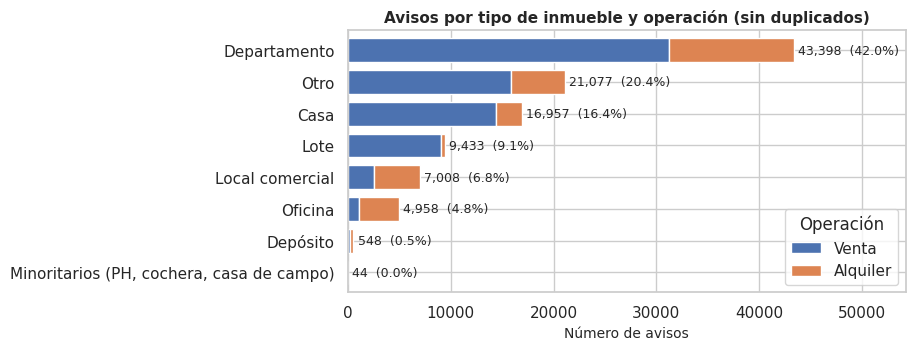

In [ ]:
# Figura 1: avisos por tipo de inmueble y operacion
tab = pd.crosstab(df.tipo, df.operation_type.replace({'Alquiler temporal': 'Alquiler'}))
tab = tab.loc[tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
tab[['Venta', 'Alquiler']].plot.barh(stacked=True, ax=ax, color=['#4C72B0', '#DD8452'], width=0.75)
for i, total in enumerate(tab.sum(axis=1)):
    ax.text(total + 400, i, f'{total:,}  ({total / len(df):.1%})', va='center', fontsize=9)
ax.set(xlim=(0, tab.sum(axis=1).max() * 1.25), xlabel='Número de avisos', ylabel='',
       title='Avisos por tipo de inmueble y operación (sin duplicados)')
ax.legend(title='Operación', loc='lower right')
guardar('fig1_tipos'); plt.show()

Casi la mitad de los avisos son departamentos (42 %) y lo que más llama la atención es que 1 de cada 5 avisos (20.4 %) está como "Otro". Es la segunda categoría más grande, o sea que si alguien filtra por tipo de inmueble se pierde más de 21 mil avisos. Esto es lo que motiva la P1. También se ve que casi todo es venta, menos oficinas y locales comerciales que son más de alquiler.

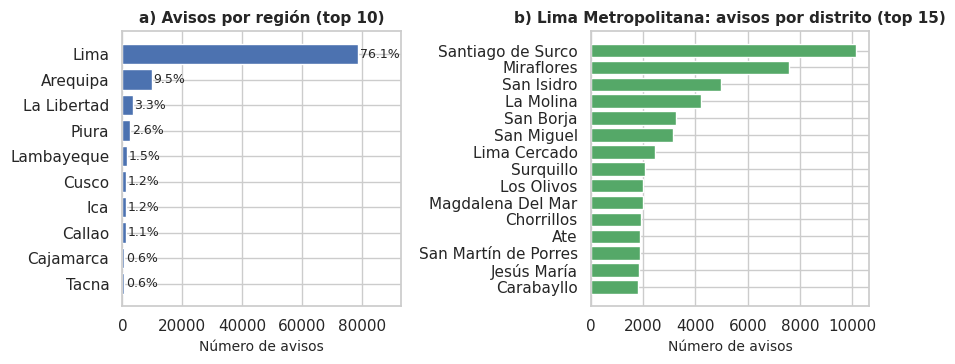

Lima Metropolitana: 74334 avisos (71.9%) | distritos: 43


In [ ]:
# Figura 2: distribucion geografica
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
reg = df.region.value_counts().head(10).sort_values()
axes[0].barh(reg.index, reg.values, color='#4C72B0')
for i, v in enumerate(reg.values):
    axes[0].text(v + 500, i, f'{v / len(df):.1%}', va='center', fontsize=9)
axes[0].set(xlim=(0, reg.max() * 1.18), title='a) Avisos por región (top 10)', xlabel='Número de avisos')
dist = df[df.es_lima_metro].distrito.value_counts().head(15).sort_values()
axes[1].barh(dist.index, dist.values, color='#55A868')
axes[1].set(title='b) Lima Metropolitana: avisos por distrito (top 15)', xlabel='Número de avisos')
plt.tight_layout(); guardar('fig2_geografia'); plt.show()
print('Lima Metropolitana:', df.es_lima_metro.sum(), f'avisos ({df.es_lima_metro.mean():.1%})', '| distritos:', df[df.es_lima_metro].distrito.nunique())

El dataset está muy concentrado en Lima: 76 % de los avisos son de la región Lima y 72 % de Lima Metropolitana (43 distritos). Arequipa es la segunda con 9.5 %. Dentro de Lima, Santiago de Surco, Miraflores y San Isidro son los distritos con más avisos. Por eso la P2 y la P3 se trabajan solo con Lima Metropolitana, que es donde hay datos suficientes.

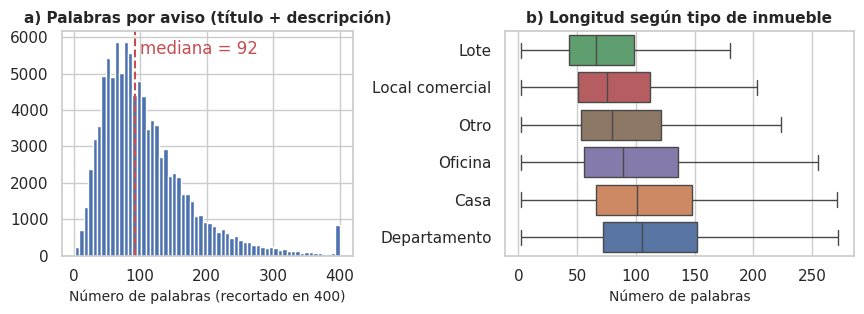

count    103423.0
mean        109.2
std          74.3
min           2.0
25%          61.0
50%          92.0
75%         138.0
max        2547.0


In [ ]:
# Figura 3: longitud de los textos
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.3), gridspec_kw={'width_ratios': [1, 1.2]})
med = df.n_palabras.median()
axes[0].hist(df.n_palabras.clip(upper=400), bins=60, color='#4C72B0')
axes[0].axvline(med, color='#C44E52', ls='--')
axes[0].text(med + 8, axes[0].get_ylim()[1] * 0.9, f'mediana = {med:.0f}', color='#C44E52')
axes[0].set(title='a) Palabras por aviso (título + descripción)', xlabel='Número de palabras (recortado en 400)')
orden = df[df.tipo.isin(CLASES_P1 + ['Otro'])].groupby('tipo').n_palabras.median().sort_values().index
sns.boxplot(data=df[df.tipo.isin(orden)], y='tipo', x='n_palabras', order=orden, showfliers=False, ax=axes[1],
            palette=[COLORES_TIPO[t] for t in orden])
axes[1].set(title='b) Longitud según tipo de inmueble', xlabel='Número de palabras', ylabel='')
plt.tight_layout(); guardar('fig3_longitud'); plt.show()
print(df.n_palabras.describe().round(1).to_string())

La mitad de los avisos tiene entre 61 y 138 palabras (mediana de 92), son textos cortos pero con bastante información. Hay pocos muy largos (hasta 2547 palabras) que en los transformers igual se van a cortar. Los departamentos y las casas tienen descripciones más largas que los lotes, tiene sentido porque describen ambientes y acabados.

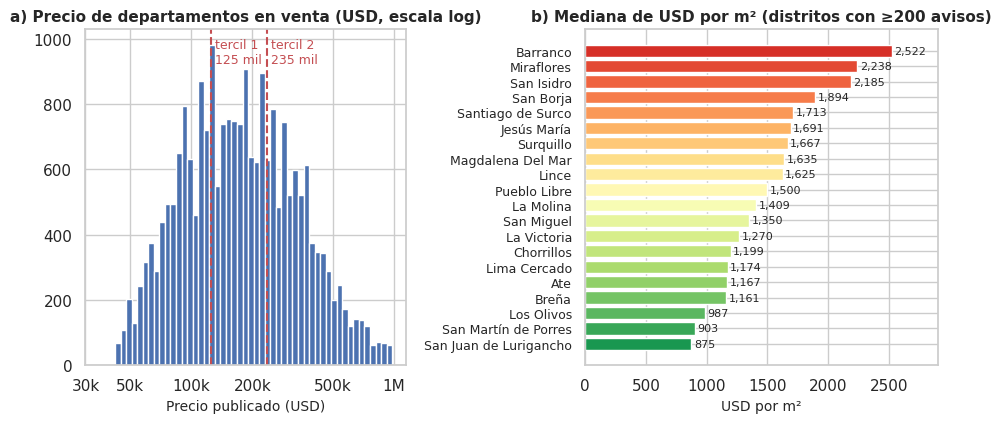

count     22509.0
mean     216712.0
std      155159.0
min       42000.0
25%      108000.0
50%      170000.0
75%      280000.0
max      980000.0
Más caro: Barranco 2522 | más barato: San Juan de Lurigancho 875


In [ ]:
# Figura 4: precios de departamentos en venta en Lima Metropolitana
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.4), gridspec_kw={'width_ratios': [1, 1.1]})
axes[0].hist(np.log10(df_p2.price), bins=50, color='#4C72B0')
for q, nombre in [(q1, 'tercil 1'), (q2, 'tercil 2')]:
    axes[0].axvline(np.log10(q), color='#C44E52', ls='--')
    axes[0].text(np.log10(q) + 0.02, axes[0].get_ylim()[1] * 0.9, f'{nombre}\n{q / 1000:,.0f} mil', color='#C44E52', fontsize=9)
ticks = [30000, 50000, 100000, 200000, 500000, 1000000]
axes[0].set_xticks(np.log10(ticks), ['30k', '50k', '100k', '200k', '500k', '1M'])
axes[0].set(title='a) Precio de departamentos en venta (USD, escala log)', xlabel='Precio publicado (USD)')

m2 = df_p2[df_p2.usd_m2.between(300, 8000)]
cnt = m2.distrito.value_counts()
top = m2[m2.distrito.isin(cnt[cnt >= 200].index)].groupby('distrito').usd_m2.median().sort_values()
axes[1].barh(top.index, top.values, color=plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(top))))
for i, v in enumerate(top.values):
    axes[1].text(v + 20, i, f'{v:,.0f}', va='center', fontsize=8)
axes[1].set(title='b) Mediana de USD por m² (distritos con ≥200 avisos)', xlabel='USD por m²', xlim=(0, top.max() * 1.15))
axes[1].tick_params(axis='y', labelsize=9)
plt.tight_layout(); guardar('fig4_precios'); plt.show()
print(df_p2.price.describe().round(0).to_string())
print('Más caro:', top.idxmax(), round(top.max()), '| más barato:', top.idxmin(), round(top.min()))

Los precios de departamentos en venta se ven mejor en escala logarítmica, la mediana está en 170 mil dólares. Los terciles cortan en 125 mil y 235 mil dólares, esos son los límites de los segmentos económico, medio y alto. El precio por m² cambia muchísimo según el distrito: Barranco, Miraflores y San Isidro pasan los 2 mil dólares por m² y San Juan de Lurigancho, San Martín de Porres y Los Olivos están por debajo de mil, casi tres veces menos. Entonces el distrito que se menciona en el texto debería ayudar bastante a predecir el segmento.

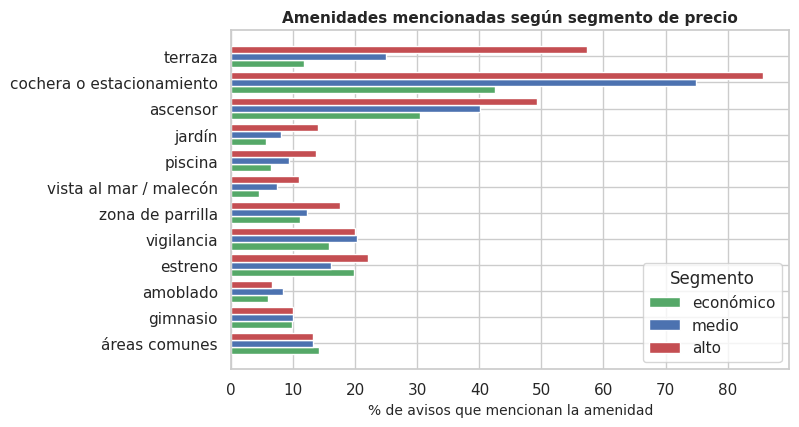

segmento,económico,medio,alto
áreas comunes,14.1,13.2,13.2
gimnasio,9.8,9.9,10.0
amoblado,5.9,8.4,6.6
estreno,19.7,16.1,22.1
vigilancia,15.7,20.3,20.0
zona de parrilla,11.1,12.2,17.5
vista al mar / malecón,4.4,7.4,11.0
piscina,6.5,9.3,13.6
jardín,5.5,8.0,14.1
ascensor,30.4,40.0,49.3


In [ ]:
# Figura 5: amenidades mencionadas segun segmento de precio (departamentos en venta, Lima)
am = df_p2.groupby('segmento')[['am_' + a for a in AMENIDADES]].mean().T * 100
am.index = list(AMENIDADES)
am = am.loc[(am['alto'] - am['económico']).sort_values().index]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
y = np.arange(len(am))
for k, seg in enumerate(['económico', 'medio', 'alto']):
    ax.barh(y + (k - 1) * 0.27, am[seg], height=0.27, color=COLORES_SEG[seg], label=seg)
ax.set_yticks(y, am.index)
ax.set(xlabel='% de avisos que mencionan la amenidad', title='Amenidades mencionadas según segmento de precio')
ax.legend(title='Segmento', loc='lower right')
guardar('fig5_amenidades'); plt.show()
am.round(1)

Hay amenidades que casi no cambian entre segmentos (gimnasio, áreas comunes, estreno) y otras que sí marcan diferencia: terraza aparece en 57 % de los avisos del segmento alto contra 12 % del económico, cochera en 86 % contra 43 % y ascensor en 49 % contra 30 %. Piscina, jardín y vista al mar también son más comunes en el alto. Esto apoya la idea de la P2 de que el texto trae señales del precio.

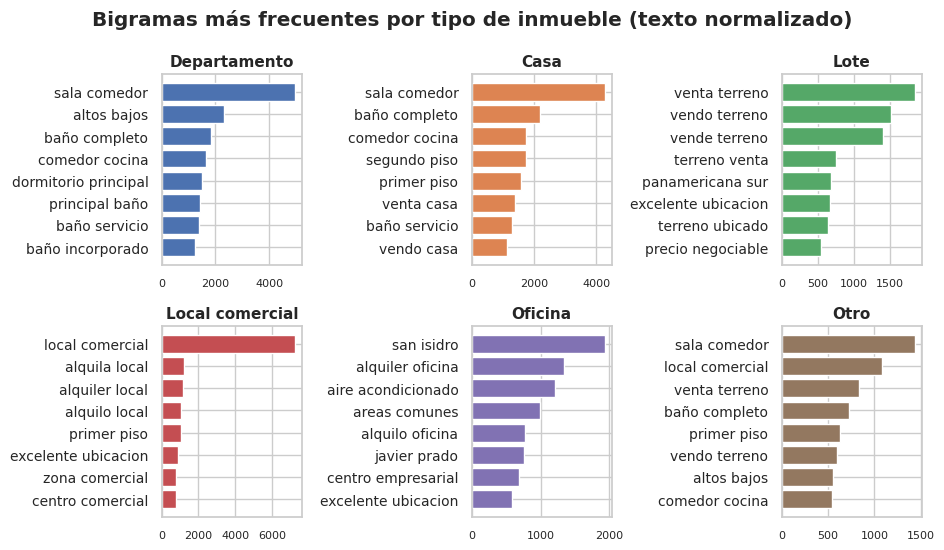

In [ ]:
# Figura 6: bigramas mas frecuentes por tipo de inmueble (sin numeros)
from sklearn.feature_extraction.text import CountVectorizer
fig, axes = plt.subplots(2, 3, figsize=(9.6, 5.6))
for ax, tp in zip(axes.ravel(), CLASES_P1 + ['Otro']):
    textos = df[df.tipo == tp].texto_norm
    textos = textos.sample(min(len(textos), 6000), random_state=SEED)
    cv = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b[a-zñ][a-zñ]+\b', min_df=5)
    frec = pd.Series(np.asarray(cv.fit_transform(textos).sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    frec = frec.sort_values(ascending=False).head(8)
    ax.barh(frec.index[::-1], frec.values[::-1], color=COLORES_TIPO[tp])
    ax.set_title(tp); ax.tick_params(axis='y', labelsize=10); ax.tick_params(axis='x', labelsize=8)
plt.suptitle('Bigramas más frecuentes por tipo de inmueble (texto normalizado)', fontweight='bold')
plt.tight_layout(); guardar('fig6_bigramas'); plt.show()

Los bigramas cambian bastante según el tipo: en departamentos salen sala comedor, baño completo y dormitorio principal; en lotes venta terreno, panamericana sur y precio negociable; en oficinas alquiler oficina, aire acondicionado, San Isidro y Javier Prado. O sea que el vocabulario sí separa los tipos y un clasificador de texto debería funcionar. En "Otro" aparecen mezclados bigramas de todos los demás (sala comedor, local comercial, venta terreno), lo que confirma que es una bolsa de avisos mal categorizados.

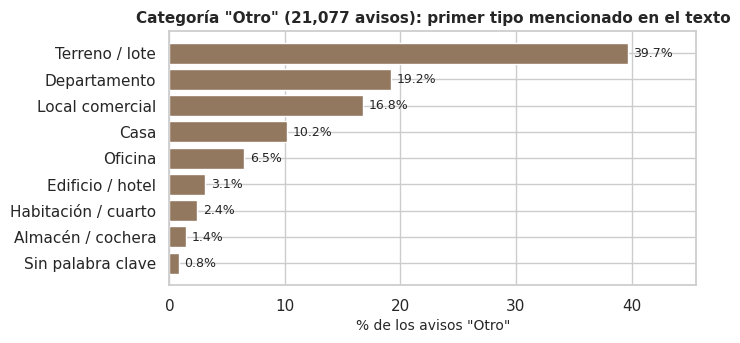

In [ ]:
# Figura 7: que hay dentro de la categoria "Otro" (primer tipo mencionado, calculado en 3.4)
comp = df_otro.clave_titulo.value_counts(normalize=True).sort_values() * 100
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.barh(comp.index, comp.values, color='#937860')
for i, v in enumerate(comp.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set(xlim=(0, comp.max() * 1.15), xlabel='% de los avisos "Otro"',
       title=f'Categoría "Otro" ({len(df_otro):,} avisos): primer tipo mencionado en el texto')
guardar('fig7_otro'); plt.show()

Viendo la primera palabra de tipo que aparece en el título, casi 40 % de los avisos "Otro" son en realidad terrenos, 19 % departamentos, 17 % locales y 10 % casas. Solo alrededor de 7 % son cosas que no están en las 5 clases (habitaciones, edificios, almacenes o cocheras) y menos de 1 % no dice nada. La gran mayoría se podría reubicar en una categoría real.

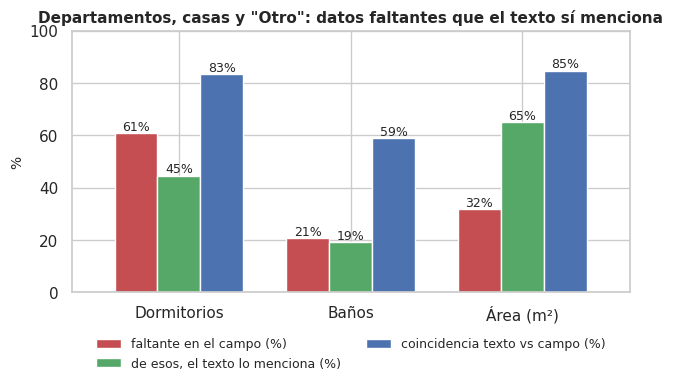

In [ ]:
# Figura 8: datos que faltan en los campos pero aparecen en el texto (tabla calculada en 3.3)
ax = info.iloc[:, :3].plot.bar(figsize=(7.2, 3.4), color=['#C44E52', '#55A868', '#4C72B0'], rot=0, width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', fontsize=9)
ax.set(ylim=(0, 100), ylabel='%', xlabel='', title='Departamentos, casas y "Otro": datos faltantes que el texto sí menciona')
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
guardar('fig8_faltantes'); plt.show()

En departamentos, casas y "Otro", al 61 % le falta el número de dormitorios y en el 45 % de esos casos el texto lo dice de forma clara. En el área se puede completar el 65 % de lo que falta. Cuando el campo sí existe, las reglas coinciden en 83 % para dormitorios y 85 % para área, pero solo en 59 % para baños: muchos avisos describen cada baño por separado (incorporado, de visita, de servicio) y el campo de Properati no los cuenta siempre igual. Por eso la P4 tiene sentido y queda espacio para probar un LLM.

## 5. Validación preliminar de la propuesta (línea base)

Antes de pasar al trabajo final probamos rápido si las preguntas se pueden responder con un modelo sencillo (TF-IDF + modelos lineales, lo visto en la sesión 2). Todas las pruebas usan una partición estratificada 80/20 con semilla fija. Estos resultados son solo un punto de partida para comparar con embeddings, transformers y LLM en el TF.

### 5.1 P1: tipo de inmueble a partir del texto

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

Xtr, Xte, ytr, yte = train_test_split(df_p1.texto_norm, df_p1.property_type, test_size=0.2,
                                      stratify=df_p1.property_type, random_state=SEED)
vec_p1 = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, max_features=200000)
A = vec_p1.fit_transform(Xtr); B = vec_p1.transform(Xte)
print('Matriz TF-IDF de entrenamiento:', A.shape)

modelos_p1 = {'Naive Bayes (Complement)': ComplementNB(alpha=0.3),
              'Regresión logística': LogisticRegression(C=5, max_iter=3000, class_weight='balanced'),
              'SVM lineal': LinearSVC(C=0.5, class_weight='balanced')}
res_p1 = []
for nombre, m in modelos_p1.items():
    t0 = time.time(); m.fit(A, ytr); pred = m.predict(B)
    res_p1.append({'modelo': 'TF-IDF + ' + nombre, 'accuracy': accuracy_score(yte, pred),
                   'F1 macro': f1_score(yte, pred, average='macro'), 'segundos': time.time() - t0})
res_p1 = pd.DataFrame(res_p1).round(3)
res_p1

Matriz TF-IDF de entrenamiento: (65403, 200000)


,modelo,accuracy,F1 macro,segundos
0,TF-IDF + Naive Bayes (Complement),0.937,0.907,0.320
1,TF-IDF + Regresión logística,0.961,0.941,45.561
2,TF-IDF + SVM lineal,0.962,0.942,2.939


                 precision    recall  f1-score   support

           Casa      0.946     0.931     0.938      3391
   Departamento      0.988     0.986     0.987      8680
Local comercial      0.908     0.931     0.919      1402
           Lote      0.929     0.947     0.938      1887
        Oficina      0.929     0.924     0.927       991

       accuracy                          0.962     16351
      macro avg      0.940     0.944     0.942     16351
   weighted avg      0.962     0.962     0.962     16351



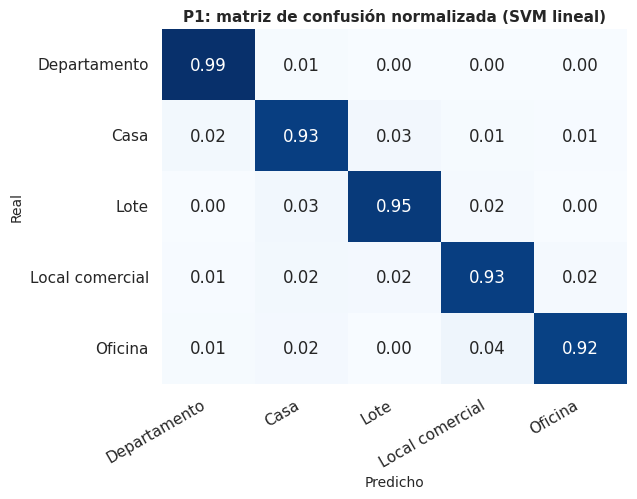

In [ ]:
mejor_p1 = modelos_p1['SVM lineal']
pred = mejor_p1.predict(B)
print(classification_report(yte, pred, digits=3))
cm = confusion_matrix(yte, pred, labels=CLASES_P1, normalize='true')
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASES_P1, yticklabels=CLASES_P1, ax=ax, cbar=False)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title('P1: matriz de confusión normalizada (SVM lineal)')
plt.xticks(rotation=30, ha='right')
guardar('p1_matriz_confusion'); plt.show()

In [ ]:
# Aplicamos el modelo a los avisos "Otro" (sin etiqueta real) para ver como se repartirian
pred_otro = mejor_p1.predict(vec_p1.transform(df_otro.texto_norm))
df_otro['tipo_predicho'] = pred_otro
reparto = pd.crosstab(df_otro.clave_titulo, df_otro.tipo_predicho)
print(pd.Series(pred_otro).value_counts(normalize=True).mul(100).round(1).to_string())
# cuando la palabra clave del titulo corresponde a una de las 5 clases, se compara con lo que predice el modelo
MAPA_CLAVE = {'Terreno / lote': 'Lote', 'Departamento': 'Departamento', 'Casa': 'Casa',
              'Local comercial': 'Local comercial', 'Oficina': 'Oficina'}
comparables = df_otro[df_otro.clave_titulo.isin(MAPA_CLAVE)]
acuerdo_otro = (comparables.clave_titulo.map(MAPA_CLAVE) == comparables.tipo_predicho).mean()
print(f'Avisos "Otro" con palabra clave de una de las 5 clases: {len(comparables)} ({len(comparables) / len(df_otro):.1%})')
print(f'Coincidencia entre la palabra clave y el modelo: {acuerdo_otro:.1%}')
reparto

Lote               40.6
Departamento       22.6
Local comercial    19.6
Casa               10.3
Oficina             6.9
Avisos "Otro" con palabra clave de una de las 5 clases: 19451 (92.3%)
Coincidencia entre la palabra clave y el modelo: 95.1%


tipo_predicho,Casa,Departamento,Local comercial,Lote,Oficina
clave_titulo,,,,,
Almacén / cochera,22,85,133,42,19
Casa,1833,24,40,222,25
Departamento,14,3996,13,13,8
Edificio / hotel,75,79,406,39,51
Habitación / cuarto,41,441,12,8,2
Local comercial,40,23,3312,112,46
Oficina,12,7,57,2,1293
Sin palabra clave,16,53,56,44,2
Terreno / lote,128,54,107,8067,3


Con TF-IDF y modelos lineales ya se llega a un F1 macro de 0.94 (SVM y regresión logística) y de 0.91 con Naive Bayes. Los errores están sobre todo entre casa y lote (avisos de casa como terreno) y entre oficina y local comercial. Al aplicar el SVM a los avisos "Otro", el 95 % de las veces coincide con la palabra clave del título, lo que da confianza. Lo que falta es que el modelo siempre obliga a escoger una de las 5 clases, por ejemplo manda las habitaciones a Departamento y los edificios a Local comercial. Para el TF hay que agregar una opción de "ninguna" (umbral de confianza o zero-shot) y revisar a mano una muestra.

### 5.2 P2: segmento de precio a partir del texto

Se compara el texto (TF-IDF con los montos enmascarados) contra un modelo que solo usa datos estructurados (distrito, área, dormitorios y baños) y contra un modelo que junta ambos, para ver cuánto aporta el texto.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
idx_tr, idx_te = train_test_split(df_p2.index, test_size=0.2, stratify=df_p2.segmento, random_state=SEED)
ytr2, yte2 = df_p2.loc[idx_tr, 'segmento'].astype(str), df_p2.loc[idx_te, 'segmento'].astype(str)

vec_p2 = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
A2 = vec_p2.fit_transform(df_p2.loc[idx_tr, 'texto_norm']); B2 = vec_p2.transform(df_p2.loc[idx_te, 'texto_norm'])
lr_p2 = LogisticRegression(C=4, max_iter=3000).fit(A2, ytr2)
pred_txt = lr_p2.predict(B2)

est = df_p2[['distrito', 'area_m2', 'bedrooms', 'bathrooms']].copy()
est['distrito'] = est.distrito.astype('category').cat.codes
hgb = HistGradientBoostingClassifier(categorical_features=[0], random_state=SEED).fit(est.loc[idx_tr], ytr2)
pred_est = hgb.predict(est.loc[idx_te])

# modelo hibrido: TF-IDF + distrito (one-hot) + area, dormitorios y banos (imputados con la mediana + indicador de nulo)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.sparse import hstack, csr_matrix

def numericas(d, ref):
    out = pd.DataFrame(index=d.index)
    for c in ['area_m2', 'bedrooms', 'bathrooms']:
        v, r = d[c], ref[c]
        if c == 'area_m2':
            v, r = np.log(v), np.log(r)
        out[c] = v.fillna(r.median())
        out[c + '_nulo'] = d[c].isna().astype(float)
    return out

tr, te = df_p2.loc[idx_tr], df_p2.loc[idx_te]
esc = StandardScaler().fit(numericas(tr, tr))
ohe = OneHotEncoder(handle_unknown='ignore').fit(tr[['distrito']].fillna('SIN DATO'))
X_tr = hstack([A2, ohe.transform(tr[['distrito']].fillna('SIN DATO')), csr_matrix(esc.transform(numericas(tr, tr)))]).tocsr()
X_te = hstack([B2, ohe.transform(te[['distrito']].fillna('SIN DATO')), csr_matrix(esc.transform(numericas(te, tr)))]).tocsr()
lr_hib = LogisticRegression(C=4, max_iter=4000).fit(X_tr, ytr2)
pred_hib = lr_hib.predict(X_te)

res_p2 = pd.DataFrame([
    {'modelo': 'Solo datos estructurados (HistGradientBoosting)', 'accuracy': accuracy_score(yte2, pred_est), 'F1 macro': f1_score(yte2, pred_est, average='macro')},
    {'modelo': 'Solo texto (TF-IDF + regresión logística)', 'accuracy': accuracy_score(yte2, pred_txt), 'F1 macro': f1_score(yte2, pred_txt, average='macro')},
    {'modelo': 'Texto + estructurados (regresión logística)', 'accuracy': accuracy_score(yte2, pred_hib), 'F1 macro': f1_score(yte2, pred_hib, average='macro')},
]).round(3)
print('Nulos en variables estructuradas (%):', (df_p2[['distrito', 'area_m2', 'bedrooms', 'bathrooms']].isna().mean() * 100).round(1).to_dict())
res_p2

Nulos en variables estructuradas (%): {'distrito': 5.9, 'area_m2': 15.6, 'bedrooms': 52.2, 'bathrooms': 7.3}


,modelo,accuracy,F1 macro
0,Solo datos estructurados (HistGradientBoosting),0.799,0.799
1,Solo texto (TF-IDF + regresión logística),0.829,0.828
2,Texto + estructurados (regresión logística),0.867,0.866


              precision    recall  f1-score   support

   económico      0.853     0.872     0.862      1535
       medio      0.755     0.745     0.750      1477
        alto      0.877     0.868     0.873      1490

    accuracy                          0.829      4502
   macro avg      0.828     0.829     0.828      4502
weighted avg      0.829     0.829     0.829      4502



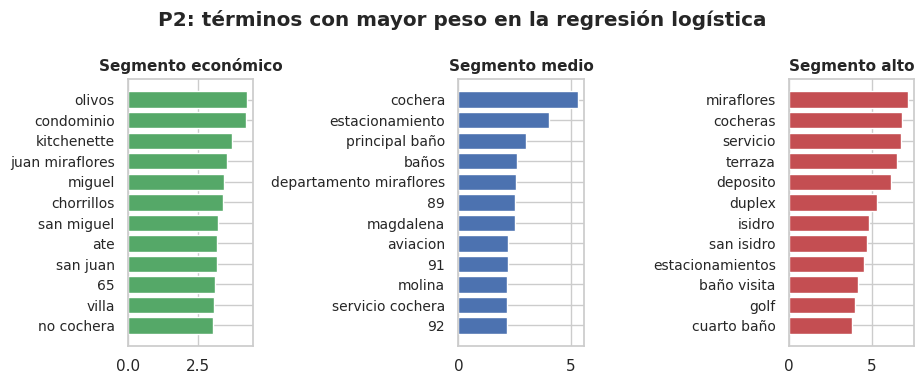

In [ ]:
orden_seg = ['económico', 'medio', 'alto']
print(classification_report(yte2, pred_txt, labels=orden_seg, digits=3))
# Figura 10 del informe: terminos con mayor peso por segmento (primer vistazo de explicabilidad)
nombres = np.array(vec_p2.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.9))
pesos = {}
for ax, seg in zip(axes, orden_seg):
    i = list(lr_p2.classes_).index(seg)
    top_i = np.argsort(lr_p2.coef_[i])[-12:]
    pesos[seg] = list(nombres[top_i][::-1])
    ax.barh(nombres[top_i], lr_p2.coef_[i][top_i], color=COLORES_SEG[seg])
    ax.set_title(f'Segmento {seg}'); ax.tick_params(axis='y', labelsize=10)
plt.suptitle('P2: términos con mayor peso en la regresión logística', fontweight='bold')
plt.tight_layout(); guardar('fig10_terminos_p2'); plt.show()

Solo con el texto (y con los montos tapados) se llega a F1 macro 0.83, más que con los datos estructurados solos (0.80). Juntando ambos sube a 0.87, entonces el texto sí aporta información que no está en los campos. El segmento medio es el más difícil (F1 0.75) porque se confunde con los otros dos, lo cual es normal porque está al medio. Los términos con más peso tienen sentido: en alto salen Miraflores, San Isidro, cocheras, terraza, dúplex, depósito y golf; en económico Los Olivos, San Juan de Miraflores, Chorrillos, Ate, condominio y kitchenette; en el medio aparecen áreas de 89 a 92 m².

### 5.3 P3: prueba de concepto de búsqueda semántica

Se codifican avisos de Lima Metropolitana con un modelo de sentence embeddings multilingüe (el mismo de las sesiones 3 y 6) y se indexan con FAISS. Luego se prueban búsquedas escritas como las haría una persona. En el TF se evaluará con Precision@K, Recall@K y MRR contra TF-IDF y BM25. En Colab conviene activar la GPU (Entorno de ejecución > Cambiar tipo de entorno).

In [ ]:
# [EMB] celda que descarga el modelo de Hugging Face
import torch, faiss
from sentence_transformers import SentenceTransformer

corpus = df[df.es_lima_metro & df.property_type.isin(['Departamento', 'Casa'])].sample(10000, random_state=SEED)
modelo_emb = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
                                 device='cuda' if torch.cuda.is_available() else 'cpu')
t0 = time.time()
emb = modelo_emb.encode(corpus.texto_modelo.str[:1000].tolist(), batch_size=128, normalize_embeddings=True,
                        show_progress_bar=False, convert_to_numpy=True).astype('float32')
index = faiss.IndexFlatIP(emb.shape[1]); index.add(emb)
print(f'{len(corpus)} avisos codificados en {time.time() - t0:.0f} s | dimensión {emb.shape[1]}')

def buscar(consulta, k=5):
    q = modelo_emb.encode([consulta], normalize_embeddings=True).astype('float32')
    sc, ids = index.search(q, k)
    r = corpus.iloc[ids[0]][['title', 'distrito', 'property_type', 'operation_type', 'bedrooms', 'price', 'currency']].copy()
    r.insert(0, 'score', sc[0].round(3))
    return r

consultas = ['departamento con vista al mar y piscina en Miraflores',
             'casa amplia con jardín para familia en La Molina',
             'minidepartamento amoblado para estudiante cerca a universidad']
demo_p3 = []
for c in consultas:
    print('\nCONSULTA:', c)
    r = buscar(c, 5)
    display(r)
    for _, fila in r.head(3).iterrows():
        demo_p3.append({'consulta': c, 'score': fila.score, 'titulo': fila.title, 'distrito': fila.distrito})
pd.DataFrame(demo_p3).to_csv('data/demo_busqueda_p3.csv', index=False)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

,score,title,distrito,property_type,operation_type,bedrooms,price,currency
81841,0.815,Departamento de 180 m² frente al mar en el malecón de Miraflores!,Miraflores,Departamento,Venta,3.0,485000.0,USD
43492,0.770,"Departamento en Alquiler con Vista al mar en Miraflores Excelente ubicación cerca a Larcomar, terraza",Miraflores,Departamento,Alquiler,NaN,2600.0,USD
76871,0.759,Alquilo hermoso departamento amoblado frente al mar en Miraflores.,Miraflores,Departamento,Alquiler,NaN,850.0,USD
72790,0.753,En Alquiler Frente al Mar! Departamento en Miraflores Amoblado!!,Miraflores,Departamento,Alquiler,2.0,1900.0,USD
14392,0.745,ALQUILER TEMPORAL EN MIRAFLORES<br>* ESPECIAL PARA EJECUTIVOS *,Miraflores,Departamento,Alquiler,2.0,1590.0,USD



CONSULTA: casa amplia con jardín para familia en La Molina


,score,title,distrito,property_type,operation_type,bedrooms,price,currency
21842,0.822,Casa con amplio jardín en Av. el Corregidor - La Molina,La Molina,Casa,Venta,4.0,682500.0,USD
71388,0.797,Residencia de lujo en el Sol de la Molina,La Molina,Casa,Venta,NaN,900000.0,USD
15911,0.786,"Preciosa casa en venta en la Molina, excelente ubicación.",La Molina,Casa,Venta,NaN,2100000.0,USD
20627,0.785,HERMOSA CASA EN AV. LOS INGENIEROS EN LA MOLINA IDEAL INVERSIONISTAS,La Molina,Casa,Venta,NaN,815000.0,USD
43152,0.779,HERMOSA CASA EN CORPAC - SAN ISIDRO,San Isidro,Casa,Venta,4.0,870000.0,USD



CONSULTA: minidepartamento amoblado para estudiante cerca a universidad


,score,title,distrito,property_type,operation_type,bedrooms,price,currency
61011,0.657,EXCLUSIVOS Y BIEN DISTRIBUIDOS DEPARTAMENTOS EN SAN MIGUEL,San Miguel,Departamento,Venta,2.0,80592.0,USD
89140,0.649,Exclusivo mini Departamento para estudiantes o ejecutivos,Lima Cercado,Departamento,Venta,NaN,195000.0,PEN
71833,0.648,"PRECIOSO DEPARTAMENTO CON SAUNA, PISCINA, GYM",NaN,Departamento,Venta,3.0,440000.0,USD
44921,0.629,Alquiler Departamento Sin Amoblar - Cerca a La Universidad de Lima - surco,San Juan de Miraflores,Departamento,Alquiler,3.0,1000.0,USD
60347,0.624,MODERNOS Y EXCLUSIVOS DEPARTAMENTOS EN BARRANCO,Barranco,Departamento,Venta,1.0,158000.0,USD


Las dos primeras búsquedas devuelven avisos bien relevantes aunque no usen las mismas palabras (frente al mar, malecón, amplio jardín). La tercera sale floja: trae departamentos en venta y hasta caros, porque el embedding entiende el tema pero no respeta condiciones como alquiler o precio. Es lo que vimos en la semana 6, similitud semántica no es lo mismo que relevancia. En el TF vamos a combinar embeddings con BM25 y filtros por metadatos (operación, distrito, precio) y evaluar con Precision@K, Recall@K y MRR.

### 5.4 P4: ¿qué tan bien extraen las reglas?

Cuando el campo estructurado sí existe se compara con lo que sacan las reglas del texto (tabla de la Figura 8). Para ver si las correcciones de la sección 3.3 sirvieron, se compara también con la primera versión de las reglas, que solo tomaba el primer número escrito antes de la palabra. Esta coincidencia es la línea base que se buscará mejorar con un LLM con salida en JSON validada (sesión 5).

In [ ]:
# primera version de las reglas (solo para comparar)
V1_DORM = re.compile(r'\b(\d{1,2}|un|uno|una|dos|tres|cuatro|cinco|seis)\s*(?:amplios?\s+|comodos?\s+|grandes?\s+)?(?:dormitorios?|habitaciones?|dorms?\b|cuartos?|recamaras?)')
V1_BANO = re.compile(r'\b(\d{1,2}|un|uno|dos|tres|cuatro|cinco)\s*(?:y medio\s+)?(?:banos?|baño|baños)\b')
V1_AREA = re.compile(r'\b(\d{2,5}(?:[.,]\d{1,2})?)\s*(?:m2|mts2|mt2|mtrs2|mts|metros cuadrados)')

def v1(pat, t):
    m = pat.search(t)
    return np.nan if m is None else float(str(NUM_PAL.get(m.group(1), m.group(1))).replace(',', '.'))

t_p4 = texto_min[base_p4.index]
antes = comparar_con_campos(base_p4, t_p4.map(lambda t: v1(V1_DORM, t)), t_p4.map(lambda t: v1(V1_BANO, t)),
                            t_p4.map(lambda t: v1(V1_AREA, t)))
comparacion = pd.DataFrame({'coincidencia, primera versión (%)': antes['coincidencia texto vs campo (%)'],
                            'coincidencia, reglas corregidas (%)': info['coincidencia texto vs campo (%)'],
                            'faltantes que se completan, primera versión (%)': antes['de esos, el texto lo menciona (%)'],
                            'faltantes que se completan, reglas corregidas (%)': info['de esos, el texto lo menciona (%)']})
comparacion.round(1)

,"coincidencia, primera versión (%)","coincidencia, reglas corregidas (%)","faltantes que se completan, primera versión (%)","faltantes que se completan, reglas corregidas (%)"
campo,,,,
Dormitorios,71.5,83.4,59.7,44.6
Baños,51.9,58.9,23.3,19.3
Área (m²),81.4,84.8,64.7,64.9


Las correcciones sí sirvieron: la coincidencia con los campos sube de 71.5 % a 83.4 % en dormitorios, de 51.9 % a 58.9 % en baños y de 81.4 % a 84.8 % en área. En dormitorios ahora se completan menos faltantes (45 % contra 60 %) porque las reglas ya no adivinan cuando el aviso da números distintos; antes se llenaban más datos pero muchos estaban mal. Baños sigue siendo lo más difícil, así que en el TF se va a probar un LLM que lea toda la descripción y devuelva los tres datos en JSON.

## 6. Dataset final

Se guarda el dataset limpio (sin duplicados, con textos anonimizados y normalizados y con las variables derivadas) en la carpeta data. Este archivo es el que se sube a la carpeta data del repositorio junto al original.

In [ ]:
cols_final = ['id', 'start_date', 'end_date', 'created_on', 'lat', 'lon', 'region', 'provincia', 'distrito', 'es_lima_metro',
              'property_type', 'operation_type', 'price', 'currency', 'price_period', 'surface_total', 'surface_covered',
              'bedrooms', 'bathrooms', 'texto_modelo', 'texto_norm', 'n_palabras', 'dorm_txt', 'banos_txt', 'area_txt',
              'area_techada_txt', 'area_terreno_txt', 'segmento_precio'] + ['am_' + a for a in AMENIDADES]
final = df[cols_final].copy()
final.to_csv('data/avisos_pe_limpio.csv.xz', index=False, compression='xz')   # xz para que pese menos de 25 MB
print('Dataset final:', final.shape, '| tamaño:', round(os.path.getsize('data/avisos_pe_limpio.csv.xz') / 1e6, 1), 'MB')
final.head(3)

Dataset final: (103423, 40) | tamaño: 25.9 MB


,id,start_date,end_date,created_on,lat,lon,region,provincia,distrito,es_lima_metro,...,am_ascensor,am_cochera o estacionamiento,am_terraza,am_vista al mar / malecón,am_estreno,am_zona de parrilla,am_vigilancia,am_amoblado,am_jardín,am_áreas comunes
0,OHnwRj8WCByyWFlzr8CG2w==,2019-06-25,2019-07-23,2019-06-25,-12.094636,-77.003267,Lima,Lima,San Borja,True,...,False,True,True,False,False,False,False,False,False,False
1,+r81Zjmgyd2Y+cguWfoHhw==,2019-06-25,2019-12-25,2019-06-25,-12.094851,-77.017706,Lima,Lima,San Isidro,True,...,False,True,True,False,False,False,False,True,True,False
2,TP2j5KyjkY1glXvrCBoqkA==,2019-06-25,2019-09-03,2019-06-25,-12.071644,-77.037922,Lima,Lima,Jesús María,True,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# resumen de resultados para el informe
resumen_final = {
    'avisos_originales': len(df_raw), 'avisos_limpios': len(df), 'avisos_lima_metro': int(df.es_lima_metro.sum()),
    'avisos_otro': len(df_otro), 'p2_departamentos': len(df_p2), 'p2_cortes_usd': [round(q1), round(q2)],
    'p1_f1_macro_svm': float(res_p1.loc[res_p1.modelo.str.contains('SVM'), 'F1 macro'].iloc[0]),
    'p2_f1_macro_texto': float(res_p2['F1 macro'].iloc[1]), 'p2_f1_macro_estructurado': float(res_p2['F1 macro'].iloc[0]),
    'p2_f1_macro_hibrido': float(res_p2['F1 macro'].iloc[2]), 'otro_acuerdo_clave_modelo': round(float(acuerdo_otro), 3),
    'p4_coincidencia': info['coincidencia texto vs campo (%)'].round(1).to_dict(),
}
resumen_final

{'avisos_originales': 124449,
 'avisos_limpios': 103423,
 'avisos_lima_metro': 74334,
 'avisos_otro': 21077,
 'p2_departamentos': 22509,
 'p2_cortes_usd': [125000, 235000],
 'p1_f1_macro_svm': 0.942,
 'p2_f1_macro_texto': 0.828,
 'p2_f1_macro_estructurado': 0.799,
 'p2_f1_macro_hibrido': 0.866,
 'otro_acuerdo_clave_modelo': 0.951,
 'p4_coincidencia': {'Dormitorios': 83.4, 'Baños': 58.9, 'Área (m²)': 84.8}}

## 7. Conclusiones del EDA

- Después de limpiar quedan 103 423 avisos únicos, 72 % de Lima Metropolitana. El texto (título + descripción) está en casi todos los avisos, mientras que dormitorios, baños o área faltan en buena parte.
- La normalización tuvo que considerar cosas propias de los avisos: HTML (28.5 % de avisos), teléfonos (10.4 %) y montos escritos en el texto (35.2 %). Los teléfonos se quitan por privacidad y los montos se enmascaran para que no haya fuga de información en la P2.
- El 20 % de los avisos está como "Otro", pero casi todos son terrenos, departamentos, locales o casas. Un SVM con TF-IDF ya llega a F1 macro 0.94 en las 5 clases.
- El texto predice el segmento de precio mejor que los datos estructurados (0.83 contra 0.80) y los dos juntos llegan a 0.87.
- Las reglas de extracción corregidas completan parte de los datos que faltan y coinciden con los campos en 83 % de los dormitorios y 85 % de las áreas, pero solo en 59 % de los baños.
- La búsqueda semántica funciona bien para consultas descriptivas, pero necesita filtros para respetar condiciones como alquiler o presupuesto.
- Para el TF queda: embeddings + clasificador, fine-tuning de un transformer en español, zero-shot para "Otro", explicabilidad con SHAP o LIME, búsqueda híbrida evaluada con P@K y MRR, y extracción de atributos con un LLM.